# Making events_long df 

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt

In [2]:
file ='/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/final_datasets/a10_lowCF_scaled_filtered_merged_with_incdec.parquet'
df= pd.read_parquet(file, engine='pyarrow')

In [3]:
df.head(7)

,grid_lat,grid_lon,h_precip_mm,datetime,no2_mean,no2_std,no2_sem,snow_ice_fraction_mean,snow_ice_fraction_std,cv_no2,...,pct_sandy_clay,pct_sandy_clay_loam,pct_sandy_loam,pct_silt,pct_silt_loam,pct_silty_clay,pct_silty_clay_loam,state_name,pre_slope,sm_class
0,36.05,-91.15,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,None
1,36.05,-91.15,NaN,2024-02-29 23:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,None
2,36.05,-91.15,NaN,2024-03-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,None
3,36.05,-91.15,NaN,2024-03-01 01:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,None
4,36.05,-91.15,NaN,2024-03-01 02:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,None
5,36.05,-91.15,NaN,2024-03-01 03:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,None
6,36.05,-91.15,NaN,2024-03-01 04:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,None


In [4]:
df.columns

Index(['grid_lat', 'grid_lon', 'h_precip_mm', 'datetime', 'no2_mean',
       'no2_std', 'no2_sem', 'snow_ice_fraction_mean', 'snow_ice_fraction_std',
       'cv_no2', 'datetime_local', 'local_hour', 'no2_scaled_by_hour',
       'pulse_start', 'sm_surface', 'surface_temp', 'soil_temp_layer1',
       'WFPS_c', 'dominant_texture', 'pct_clay', 'pct_clay_loam', 'pct_loam',
       'pct_loamy_sand', 'pct_sand', 'pct_sandy_clay', 'pct_sandy_clay_loam',
       'pct_sandy_loam', 'pct_silt', 'pct_silt_loam', 'pct_silty_clay',
       'pct_silty_clay_loam', 'state_name', 'pre_slope', 'sm_class'],
      dtype='object')

In [5]:
df = df.copy()
df["datetime"] = pd.to_datetime(df["datetime"])
df["datetime_local"] = pd.to_datetime(df["datetime_local"])
df = df.sort_values(["grid_lat", "grid_lon", "datetime"]).reset_index(drop=True)

In [6]:
#columns to keep 
keep_cols = [
    "dominant_texture", "pct_clay", "pct_clay_loam", "pct_loam",
    "pct_loamy_sand", "pct_sand", "pct_sandy_clay", "pct_sandy_clay_loam",
    "pct_sandy_loam", "pct_silt", "pct_silt_loam", "pct_silty_clay",
    "pct_silty_clay_loam", "state_name", "datetime_local", "pre_slope", "sm_class"]

#variables to average within each lag day 
avg_cols = [
    "no2_mean",
    'sm_surface',
    "WFPS_c",
    "h_precip_mm",
    "surface_temp",
    "soil_temp_layer1"
]

In [7]:
#get pulse rows and give ID 
pulse_df = df[df["pulse_start"] ==True].copy().reset_index(drop=True)

#give each pulse a unique ID
pulse_df["event_id"] =np.arange(len(pulse_df))
records =[]

In [8]:
from tqdm import tqdm

In [9]:
# build windows with progress bar
for _, pulse in tqdm(pulse_df.iterrows(), total=len(pulse_df), desc="building event windows"):
    lat =pulse["grid_lat"]
    lon = pulse["grid_lon"]
    t0 =pulse["datetime"]

    #all data at this grid cell
    sub =df[(df["grid_lat"] ==lat) & (df["grid_lon"] ==lon)].copy()

    #keep only +/- 7 day window
    sub = sub[
        (sub["datetime"] >= t0 - pd.Timedelta(days=7)) &
        (sub["datetime"] <= t0 + pd.Timedelta(days=7))
    ].copy()

    if sub.empty:
        continue

    #lag in integer days relative to pulse time
    sub["lag_days"] =((sub["datetime"] - t0) / pd.Timedelta(days=1)).apply(np.floor).astype(int)

    #keep only exact lag bins -7 ... +7
    sub = sub[(sub["lag_days"] >= -7) & (sub["lag_days"] <= 7)].copy()

    #daily averages for certain variables
    grouped =(sub.groupby("lag_days", as_index=False)[avg_cols].mean())

    #add pulse data back onto every lag row
    grouped["event_id"] = pulse["event_id"]
    grouped["grid_lat"] = lat
    grouped["grid_lon"] = lon
    grouped["datetime_event"] = t0
    grouped["pulse_date"] = t0.normalize()

    for col in keep_cols:
        grouped[col] = pulse[col]

    records.append(grouped)

building event windows: 100%|██████████| 2009/2009 [02:19<00:00, 14.41it/s]


In [10]:
#combine into events_long
events_long = pd.concat(records, ignore_index=True)
front_cols = ["event_id", "grid_lat", "grid_lon", "datetime_event", "pulse_date", "lag_days",
              "no2_mean","WFPS_c", "sm_surface", "h_precip_mm", "surface_temp", "soil_temp_layer1"]

events_long = events_long[front_cols + keep_cols]
events_long = events_long.sort_values(["event_id", "lag_days"]).reset_index(drop=True)
events_long.head()

,event_id,grid_lat,grid_lon,datetime_event,pulse_date,lag_days,no2_mean,WFPS_c,sm_surface,h_precip_mm,...,pct_sandy_clay_loam,pct_sandy_loam,pct_silt,pct_silt_loam,pct_silty_clay,pct_silty_clay_loam,state_name,datetime_local,pre_slope,sm_class
0,0,36.05,-91.15,2024-04-13 15:00:00,2024-04-13,-7,2.013325e+15,0.275983,0.124556,NaN,...,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,2024-04-13 10:00:00,0.000848,increasing
1,0,36.05,-91.15,2024-04-13 15:00:00,2024-04-13,-6,NaN,0.306866,0.138481,NaN,...,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,2024-04-13 10:00:00,0.000848,increasing
2,0,36.05,-91.15,2024-04-13 15:00:00,2024-04-13,-5,1.832545e+15,0.254981,0.115120,NaN,...,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,2024-04-13 10:00:00,0.000848,increasing
3,0,36.05,-91.15,2024-04-13 15:00:00,2024-04-13,-4,NaN,0.263618,0.118996,NaN,...,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,2024-04-13 10:00:00,0.000848,increasing
4,0,36.05,-91.15,2024-04-13 15:00:00,2024-04-13,-3,NaN,0.458100,0.206703,NaN,...,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,2024-04-13 10:00:00,0.000848,increasing


In [11]:
events_long.columns

Index(['event_id', 'grid_lat', 'grid_lon', 'datetime_event', 'pulse_date',
       'lag_days', 'no2_mean', 'WFPS_c', 'sm_surface', 'h_precip_mm',
       'surface_temp', 'soil_temp_layer1', 'dominant_texture', 'pct_clay',
       'pct_clay_loam', 'pct_loam', 'pct_loamy_sand', 'pct_sand',
       'pct_sandy_clay', 'pct_sandy_clay_loam', 'pct_sandy_loam', 'pct_silt',
       'pct_silt_loam', 'pct_silty_clay', 'pct_silty_clay_loam', 'state_name',
       'datetime_local', 'pre_slope', 'sm_class'],
      dtype='object')

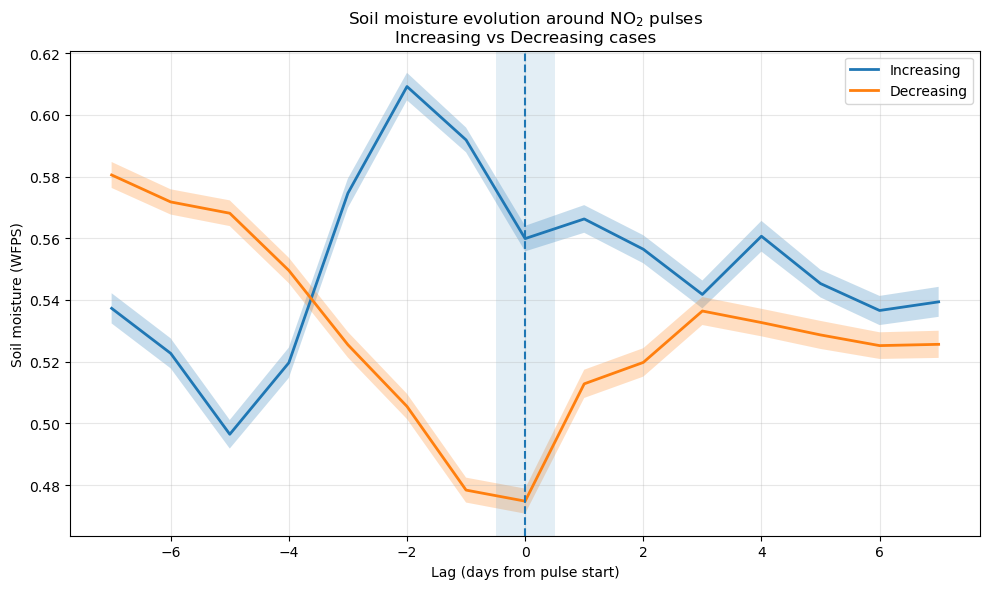

In [12]:
plot_df = events_long.copy()

#keep only two classes 
plot_df = plot_df[plot_df["sm_class"].isin(["increasing", "decreasing"])].copy()

#drop missing values needed for plotting
plot_df = plot_df.dropna(subset=["lag_days", "WFPS_c", "sm_class"])

#compute mean + SEM by lag
summary = (plot_df.groupby(["sm_class", "lag_days"])["WFPS_c"].agg(["mean", "std", "count"]).reset_index())
summary["sem"] =summary["std"] / np.sqrt(summary["count"])

#split out the two classes
inc =summary[summary["sm_class"] == "increasing"].copy()
dec =summary[summary["sm_class"] == "decreasing"].copy()

#ploting
fig, ax = plt.subplots(figsize=(10, 6))

#increasing
ax.plot(inc["lag_days"],inc["mean"],label="Increasing",linewidth=2)
ax.fill_between(inc["lag_days"],inc["mean"] - inc["sem"],inc["mean"] + inc["sem"],alpha=0.25)

#decreasing
ax.plot(dec["lag_days"],dec["mean"],label="Decreasing",linewidth=2)
ax.fill_between(dec["lag_days"],dec["mean"] - dec["sem"],dec["mean"] + dec["sem"], alpha=0.25)

#pulse day marker
ax.axvline(0, linestyle="--", linewidth=1.5)
ax.axvspan(-0.5, 0.5, alpha=0.12)

ax.set_xlabel("Lag (days from pulse start)")
ax.set_ylabel("Soil moisture (WFPS)")
ax.set_title("Soil moisture evolution around NO$_2$ pulses\nIncreasing vs Decreasing cases")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

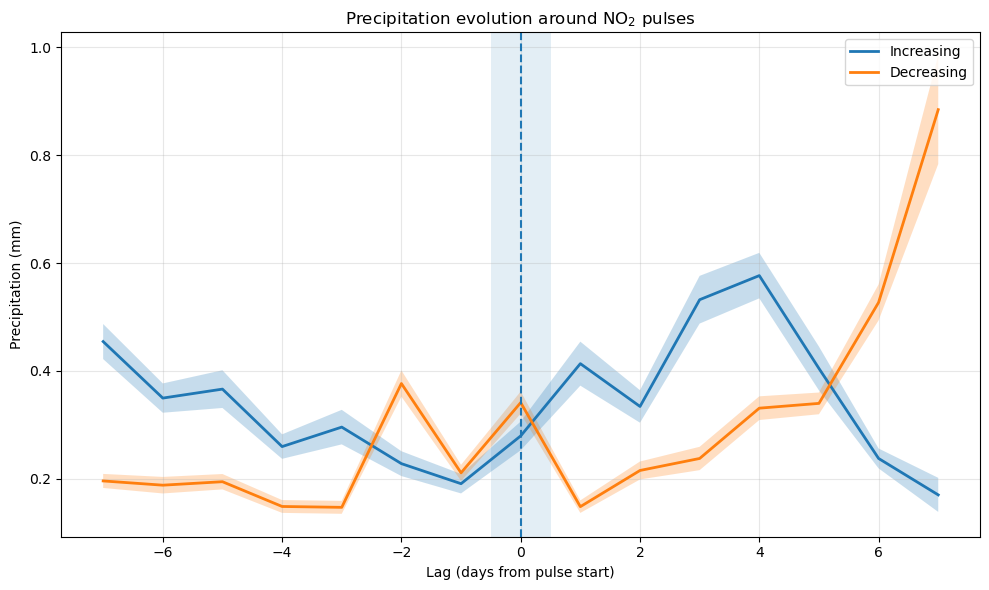

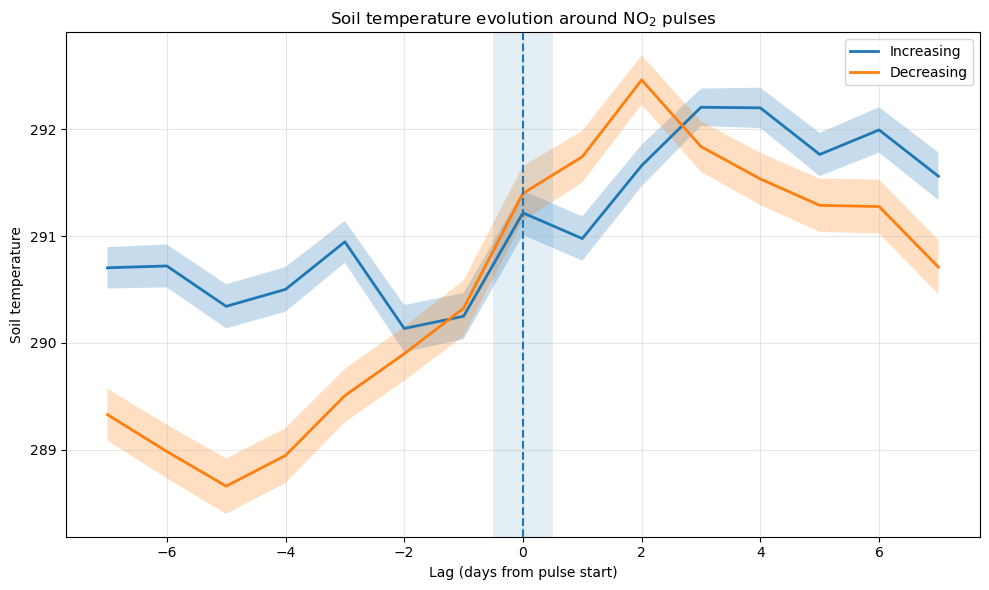

In [13]:
plot_df = events_long.copy()

plot_df =plot_df[plot_df["sm_class"].isin(["increasing", "decreasing"])].copy()
plot_df =plot_df.dropna(subset=["event_id", "lag_days", "sm_class"])

event_lag = (plot_df.groupby(["sm_class", "event_id", "lag_days"], as_index=False)[
             ["h_precip_mm", "soil_temp_layer1"]].mean())

#summary statistics 
summary =(event_lag.groupby(["sm_class", "lag_days"])[["h_precip_mm", "soil_temp_layer1"]]
          .agg(["mean", "std", "count"])
          .reset_index())

# flatten multi-index columns
summary.columns = ["sm_class", "lag_days",
                   "precip_mean", "precip_std", "precip_count",
                   "soiltemp_mean", "soiltemp_std", "soiltemp_count"]

summary["precip_sem"] =summary["precip_std"] /np.sqrt(summary["precip_count"])
summary["soiltemp_sem"]= summary["soiltemp_std"] /np.sqrt(summary["soiltemp_count"])

inc =summary[summary["sm_class"] =="increasing"].copy()
dec =summary[summary["sm_class"] =="decreasing"].copy()

#plot precip
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(inc["lag_days"], inc["precip_mean"], label="Increasing", linewidth=2)
ax.fill_between(inc["lag_days"],
                inc["precip_mean"] - inc["precip_sem"],
                inc["precip_mean"] + inc["precip_sem"],
                alpha=0.25)

ax.plot(dec["lag_days"], dec["precip_mean"], label="Decreasing", linewidth=2)
ax.fill_between(dec["lag_days"],
                dec["precip_mean"] - dec["precip_sem"],
                dec["precip_mean"] + dec["precip_sem"],
                alpha=0.25)

ax.axvline(0, linestyle="--", linewidth=1.5)
ax.axvspan(-0.5, 0.5, alpha=0.12)

ax.set_xlabel("Lag (days from pulse start)")
ax.set_ylabel("Precipitation (mm)")
ax.set_title("Precipitation evolution around NO$_2$ pulses")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

#plot soil temp
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(inc["lag_days"], inc["soiltemp_mean"], label="Increasing", linewidth=2)
ax.fill_between(inc["lag_days"],
                inc["soiltemp_mean"] - inc["soiltemp_sem"],
                inc["soiltemp_mean"] + inc["soiltemp_sem"],
                alpha=0.25)

ax.plot(dec["lag_days"], dec["soiltemp_mean"], label="Decreasing", linewidth=2)
ax.fill_between(dec["lag_days"],
                dec["soiltemp_mean"] - dec["soiltemp_sem"],
                dec["soiltemp_mean"] + dec["soiltemp_sem"],
                alpha=0.25)

ax.axvline(0, linestyle="--", linewidth=1.5)
ax.axvspan(-0.5, 0.5, alpha=0.12)

ax.set_xlabel("Lag (days from pulse start)")
ax.set_ylabel("Soil temperature")
ax.set_title("Soil temperature evolution around NO$_2$ pulses")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [15]:
#prepulse window
pre_df = event_lag[event_lag["lag_days"] < 0].copy()
pre_df["h_precip_mm"] =pre_df["h_precip_mm"].fillna(0)

#compute per event precip
event_metrics = (
    pre_df.groupby(["sm_class", "event_id"])
    .apply(lambda g: pd.Series({
        "total_precip_pre": g["h_precip_mm"].sum(),
        "max_precip": g["h_precip_mm"].max(),
        "lag_of_max_precip": g.loc[g["h_precip_mm"].idxmax(), "lag_days"]
    }))
    .reset_index())

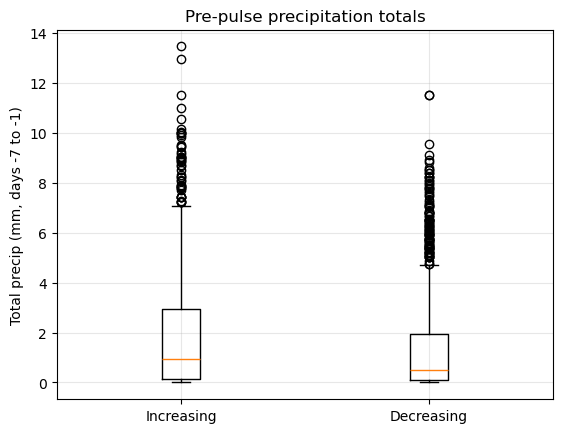

In [16]:
inc = event_metrics[event_metrics["sm_class"] == "increasing"]["total_precip_pre"]
dec = event_metrics[event_metrics["sm_class"] == "decreasing"]["total_precip_pre"]

plt.boxplot([inc, dec])
plt.xticks([1, 2], ["Increasing", "Decreasing"])
plt.ylabel("Total precip (mm, days -7 to -1)")
plt.title("Pre-pulse precipitation totals")
plt.grid(True, alpha=0.3)
plt.show()

In [19]:
events_long

,event_id,grid_lat,grid_lon,datetime_event,pulse_date,lag_days,no2_mean,WFPS_c,sm_surface,h_precip_mm,...,pct_sandy_clay_loam,pct_sandy_loam,pct_silt,pct_silt_loam,pct_silty_clay,pct_silty_clay_loam,state_name,datetime_local,pre_slope,sm_class
0,0,36.05,-91.15,2024-04-13 15:00:00,2024-04-13,-7,2.013325e+15,0.275983,0.124556,NaN,...,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,2024-04-13 10:00:00,0.000848,increasing
1,0,36.05,-91.15,2024-04-13 15:00:00,2024-04-13,-6,NaN,0.306866,0.138481,NaN,...,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,2024-04-13 10:00:00,0.000848,increasing
2,0,36.05,-91.15,2024-04-13 15:00:00,2024-04-13,-5,1.832545e+15,0.254981,0.115120,NaN,...,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,2024-04-13 10:00:00,0.000848,increasing
3,0,36.05,-91.15,2024-04-13 15:00:00,2024-04-13,-4,NaN,0.263618,0.118996,NaN,...,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,2024-04-13 10:00:00,0.000848,increasing
4,0,36.05,-91.15,2024-04-13 15:00:00,2024-04-13,-3,NaN,0.458100,0.206703,NaN,...,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,2024-04-13 10:00:00,0.000848,increasing
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30128,2008,48.55,-99.85,2024-07-06 15:00:00,2024-07-06,3,NaN,0.440964,0.193836,0.014792,...,0.0,41.666667,0.0,0.000000,0.000000,0.000000,North Dakota,2024-07-06 10:00:00,-0.000573,decreasing
30129,2008,48.55,-99.85,2024-07-06 15:00:00,2024-07-06,4,NaN,0.393795,0.173095,0.000000,...,0.0,41.666667,0.0,0.000000,0.000000,0.000000,North Dakota,2024-07-06 10:00:00,-0.000573,decreasing
30130,2008,48.55,-99.85,2024-07-06 15:00:00,2024-07-06,5,9.124734e+14,0.368646,0.162024,0.000000,...,0.0,41.666667,0.0,0.000000,0.000000,0.000000,North Dakota,2024-07-06 10:00:00,-0.000573,decreasing
30131,2008,48.55,-99.85,2024-07-06 15:00:00,2024-07-06,6,1.082669e+15,0.355016,0.156042,0.000000,...,0.0,41.666667,0.0,0.000000,0.000000,0.000000,North Dakota,2024-07-06 10:00:00,-0.000573,decreasing


In [20]:
events_long.columns

Index(['event_id', 'grid_lat', 'grid_lon', 'datetime_event', 'pulse_date',
       'lag_days', 'no2_mean', 'WFPS_c', 'sm_surface', 'h_precip_mm',
       'surface_temp', 'soil_temp_layer1', 'dominant_texture', 'pct_clay',
       'pct_clay_loam', 'pct_loam', 'pct_loamy_sand', 'pct_sand',
       'pct_sandy_clay', 'pct_sandy_clay_loam', 'pct_sandy_loam', 'pct_silt',
       'pct_silt_loam', 'pct_silty_clay', 'pct_silty_clay_loam', 'state_name',
       'datetime_local', 'pre_slope', 'sm_class'],
      dtype='object')

In [21]:
event_lag = (
    events_long
    .groupby(["sm_class", "event_id", "lag_days"], as_index=False)
    .agg({
        "h_precip_mm": "mean",
        "soil_temp_layer1": "mean",
        "sm_surface": "mean",
        "dominant_texture": "first",   #<-- keep soil info
        "state_name": "first"
    })
)

In [22]:
texture_map = {
    "sand": "coarse",
    "loamy sand": "coarse",
    "sandy loam": "moderately_coarse",
    
    "loam": "medium",
    "silt loam": "medium",
    "silt": "medium",
    
    "clay loam": "fine",
    "silty clay loam": "fine",
    "sandy clay loam": "fine",
    
    "clay": "very_fine",
    "silty clay": "very_fine",
    "sandy clay": "very_fine"
}

event_lag["soil_group"] = event_lag["dominant_texture"].map(texture_map)

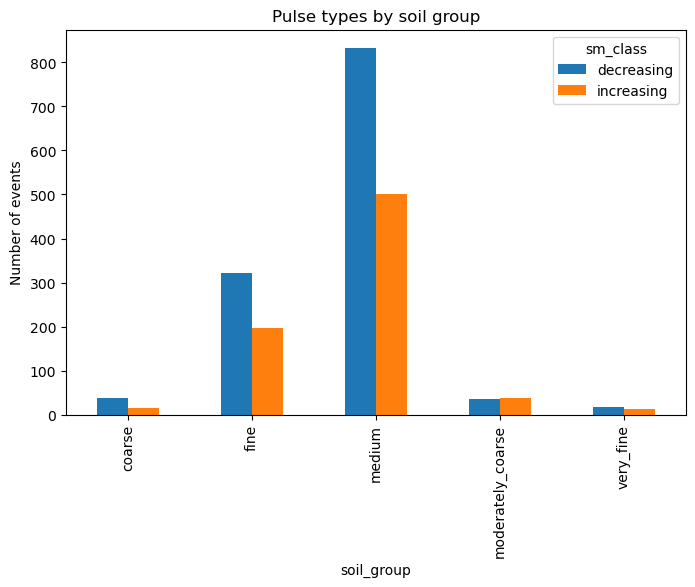

In [23]:
counts = (event_lag.groupby(["soil_group", "sm_class"])["event_id"].nunique().unstack())

counts.plot(kind="bar", figsize=(8,5))
plt.ylabel("Number of events")
plt.title("Pulse types by soil group")
plt.show()

In [25]:
import seaborn as sns

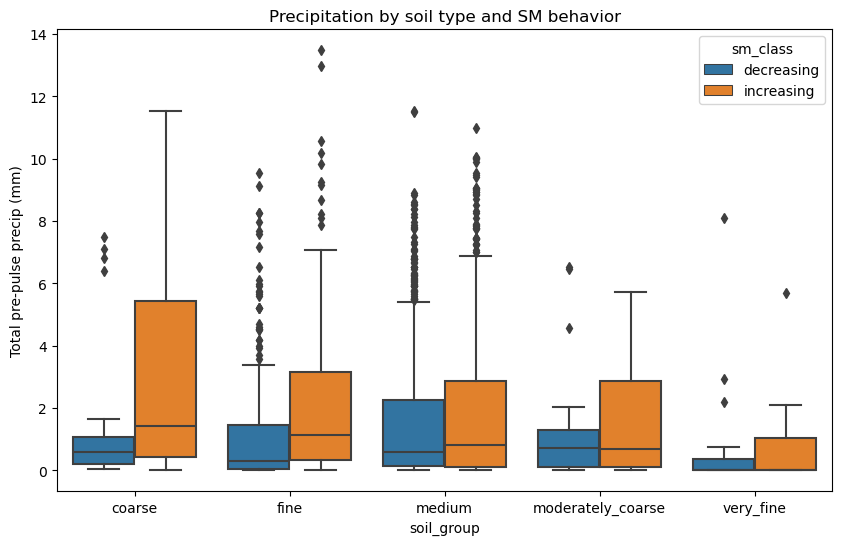

In [26]:
pre_df = event_lag[event_lag["lag_days"] <0].copy()

event_precip = (pre_df.groupby(["soil_group", "sm_class", "event_id"])["h_precip_mm"].sum()
                .reset_index())

plt.figure(figsize=(10,6))
sns.boxplot(data=event_precip,x="soil_group",y="h_precip_mm",hue="sm_class")

plt.ylabel("Total pre-pulse precip (mm)")
plt.title("Precipitation by soil type and SM behavior")
plt.show()

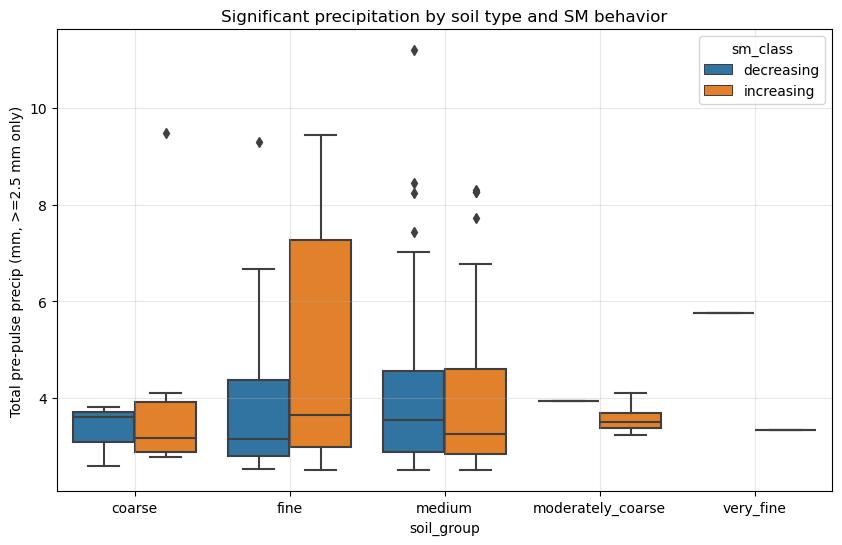

In [27]:
pre_df = event_lag[event_lag["lag_days"] <0].copy() #pre-pulse window 

# apply a precip threshold
pre_df["h_precip_mm_thresh"] = pre_df["h_precip_mm"].where(pre_df["h_precip_mm"] >= 2.5, 0)

#sum precip per event
event_precip = ( pre_df.groupby(["soil_group", "sm_class", "event_id"])["h_precip_mm_thresh"].sum()
                .reset_index())

#dropping events with no rainfall 
event_precip = event_precip[event_precip["h_precip_mm_thresh"] > 0]

plt.figure(figsize=(10,6))
sns.boxplot(data=event_precip,x="soil_group",y="h_precip_mm_thresh",hue="sm_class")

plt.ylabel("Total pre-pulse precip (mm, >=2.5 mm only)")
plt.title("Significant precipitation by soil type and SM behavior")
plt.grid(True, alpha=0.3)
plt.show()

In [31]:
pulse_df = df[df["pulse_start"] == True].copy()

In [32]:
pulse_df = pulse_df.dropna(subset=["no2_mean"])

In [33]:
pulse_df['no2_mean'].describe()

count    2.009000e+03
mean     3.392821e+15
std      1.423164e+15
min      1.452637e+15
25%      2.560076e+15
50%      3.048352e+15
75%      3.763359e+15
max      1.944495e+16
Name: no2_mean, dtype: float64

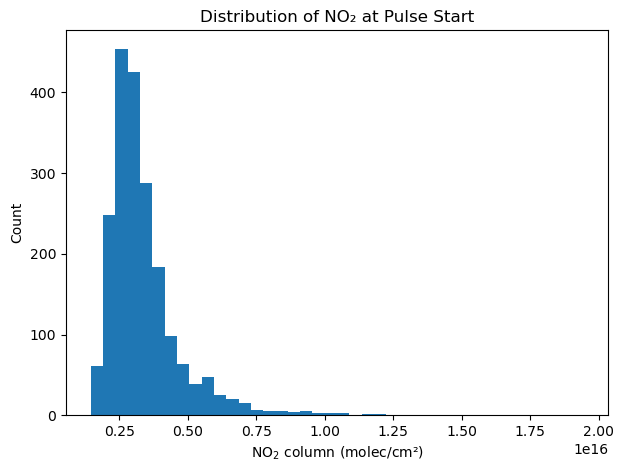

In [34]:
plt.figure(figsize=(7,5))
plt.hist(pulse_df["no2_mean"], bins=40)
plt.xlabel("NO$_2$ column (molec/cm²)")
plt.ylabel("Count")
plt.title("Distribution of NO$_2$ at Pulse Start")
plt.show()

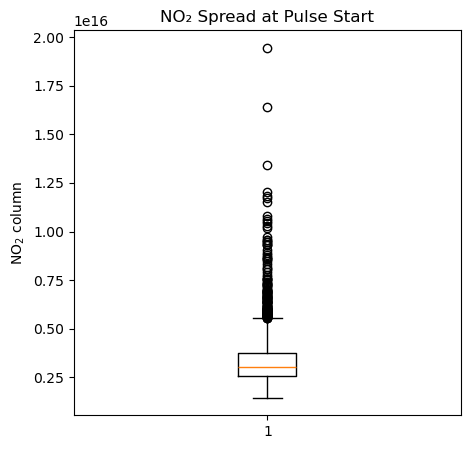

In [36]:
plt.figure(figsize=(5,5))
plt.boxplot(pulse_df["no2_mean"], vert=True)
plt.ylabel("NO$_2$ column")
plt.title("NO₂ Spread at Pulse Start")
plt.show()

In [37]:
output_file = '/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/final_datasets/a10_lowCF_scaled_7day_events_long.parquet'
events_long.to_parquet(output_file, engine='pyarrow')

In [38]:
events_long.head()

,event_id,grid_lat,grid_lon,datetime_event,pulse_date,lag_days,no2_mean,WFPS_c,sm_surface,h_precip_mm,...,pct_sandy_clay_loam,pct_sandy_loam,pct_silt,pct_silt_loam,pct_silty_clay,pct_silty_clay_loam,state_name,datetime_local,pre_slope,sm_class
0,0,36.05,-91.15,2024-04-13 15:00:00,2024-04-13,-7,2.013325e+15,0.275983,0.124556,NaN,...,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,2024-04-13 10:00:00,0.000848,increasing
1,0,36.05,-91.15,2024-04-13 15:00:00,2024-04-13,-6,NaN,0.306866,0.138481,NaN,...,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,2024-04-13 10:00:00,0.000848,increasing
2,0,36.05,-91.15,2024-04-13 15:00:00,2024-04-13,-5,1.832545e+15,0.254981,0.115120,NaN,...,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,2024-04-13 10:00:00,0.000848,increasing
3,0,36.05,-91.15,2024-04-13 15:00:00,2024-04-13,-4,NaN,0.263618,0.118996,NaN,...,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,2024-04-13 10:00:00,0.000848,increasing
4,0,36.05,-91.15,2024-04-13 15:00:00,2024-04-13,-3,NaN,0.458100,0.206703,NaN,...,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,2024-04-13 10:00:00,0.000848,increasing
